<a href="https://colab.research.google.com/github/nfdk25/ML/blob/main/02_Regresi%C3%B3nLineal_Clase15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Regresión lineal con Python
#Introducción


La regresión lineal es un método estadístico que trata de modelar la relación entre una variable continua y una o más variables independientes mediante el ajuste de una ecuación lineal. Se llama regresión lineal simple cuando solo hay una variable independiente y regresión lineal múltiple cuando hay más de una.



##Modelos de regresión lineal en Python

Dos de las implementaciones de modelos de regresión lineal más utilizadas en Python son: scikit-learn y statsmodels. Scikit-learn está orientada principalmente a la predicción, por lo apenas tiene funcionalidades que muestren las muchas características del modelo que se deben analizar para hacer inferencia. Statsmodels es mucho más completo en este sentido.


#Definición matemática


Una definición que se encuentra con frecuencia en los libros de estadística es:

$$y_i=β_0+β_1x_{i1}+β_2x_{i2}+...+β_px_{ip}+ϵ_i$$

Se hace referencia al valor de $y$ para una observación  $i$  concreta. El valor de una observación puntual nunca va a ser exactamente igual al promedio, de ahí que se añada el término de error $ϵ$.

La interpretación de los elementos del modelo es:

- $β_0$ : es la ordenada en el origen, se corresponde con el valor promedio de la variable respuesta $y$ cuando todos los predictores son cero.

- $β_j$ : es el efecto promedio que tiene sobre la variable respuesta el incremento en una unidad de la variable predictora $x_j$, manteniéndose constantes el resto de variables. Se conocen como coeficientes de regresión.

- $ϵ_i$ : es el residuo o error irreducible, la diferencia entre el valor observado y el estimado por el modelo. Recoge el efecto de todas aquellas variables que influyen en $y$  pero que no se incluyen en el modelo como predictores.

En la gran mayoría de casos, los valores $β_0$  y $β_j$ poblacionales se desconocen, por lo que, a partir de una muestra, se obtienen sus estimaciones  $\hat{β}_0$  y  $\hat{β}_j$ . Ajustar el modelo consiste en estimar, a partir de los datos disponibles, los valores de los coeficientes de regresión que maximizan la verosimilitud, es decir, los que dan lugar al modelo que con mayor probabilidad puede haber generado los datos observados.
El método empleado con más frecuencia es el ajuste por mínimos cuadrados ordinarios (OLS), que identifica como mejor modelo la recta (o plano/hiperplano si es regresión múltiple) que minimiza la suma de las desviaciones verticales entre cada dato de entrenamiento y la recta, elevadas al cuadrado.

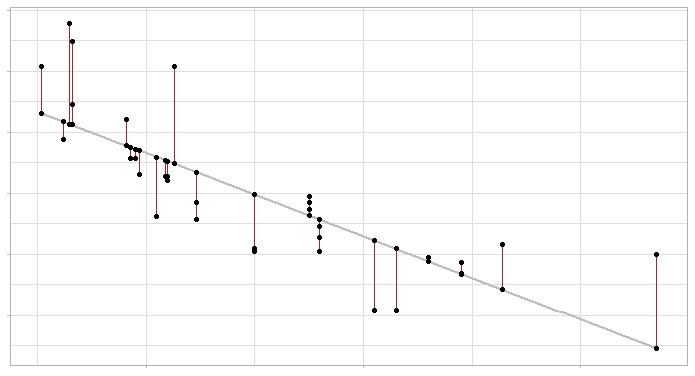

*Figura: Modelo de regresión lineal y sus errores: la línea gris representa la recta de regresión (el modelo) y los segmentos rojos el error entre esta y cada observación.*


#Interpretación del modelo


Los principales elementos que hay que interpretar en un modelo de regresión lineal son los coeficientes de los predictores:

- $β_0$  es la ordenada en el origen o intercepto, se corresponde con el valor esperado de la variable respuesta  $y$  cuando todos los predictores son cero.

- $β_j$  los coeficientes de regresión parcial de cada predictor indican el cambio promedio esperado de la variable respuesta  y  al incrementar en una unidad de la variable predictora  $x_j$ , manteniéndose constantes el resto de variables.

La magnitud de cada coeficiente parcial de regresión depende de las unidades en las que se mida la variable predictora a la que corresponde, por lo que su magnitud no está asociada con la importancia de cada predictor.


##Significado "lineal"

El término "lineal" en los modelos de regresión hace referencia al hecho de que los parámetros se incorporan en la ecuación de forma lineal, no a que necesariamente la relación entre cada predictor y la variable respuesta tenga que seguir un patrón lineal.

La siguiente ecuación muestra un modelo lineal en el que el predictor  $x_1$  no es lineal respecto a $y$:

$$y=β_0+β_1x_1+β_2log(x_1)+ϵ$$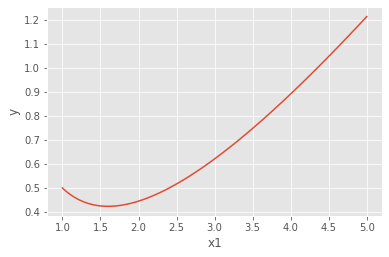

En contraposición, el siguiente no es un modelo lineal:

$$y=β_0+β_1x^{β2}_1+ϵ$$


#Bondad de ajuste del modelo


Una vez ajustado el modelo, es necesario verificar su utilidad ya que, aun siendo la línea que mejor se ajusta a las observaciones de entre todas las posibles, puede tener un gran error. Las métricas más utilizadas para medir la calidad del ajuste son: el error estándar de los residuos y el coeficiente de determinación $R^2$.

##Error estándar de los residuos (Residual Standard Error, RSE)

Mide la desviación promedio de cualquier punto estimado por el modelo respecto de la recta de regresión. Tiene las mismas unidades que la variable respuesta. Se puede obtener una aproximacion, un % de la desviación (se denomina Relative Square Error).

$$RSS = ∑^n_{i=1} (y_i - \hat{y_i})^2$$ $$        RSE=\sqrt{\frac{1}{n−p−1}RSS}$$



##Coeficiente de determinación  $R^2$

$R^2$  describe la proporción de varianza de la variable respuesta explicada por el modelo y relativa a la varianza total. Su valor está acotado entre 0 y 1, siendo mas facil de interpretar.

$$R^2=\frac{\text{Suma de cuadrados totales - Suma de cuadrados residuales}}{\text{Suma de cuadrados totales}}=$$

$$1−\frac{\text{Suma de cuadrados residuales}}{\text{Suma de cuadrados totales}}=$$

$$1−\frac{\sum{(\hat{y}_i −y_i)^2}}{\sum{(y_i−\bar{y}_i)^2}}$$


En los modelos lineales múltiples, cuantos más predictores se incluyan en el modelo, mayor es el valor de  $R^2$ . Esto es así ya que, por poco que sea, cada predictor va a explicar una parte de la variabilidad observada en  $y$ . Es por esto que  $R^2$  no puede utilizarse para comparar modelos con distinto número de predictores.

$R^2_{ajustado}$ introduce una penalización al valor de $R^2$  por cada predictor que se añade al modelo. El valor de la penalización depende del número de predictores utilizados y del tamaño de la muestra. Cuanto mayor es el tamaño de la muestra, más predictores se pueden incorporar en el modelo. $R^2_{ajustado}$ permite encontrar el mejor modelo, aquel que consigue explicar mejor la variabilidad de $y$ con el menor número de predictores.

$$R^2_{ajustado}=1−\frac{SSE}{SST}x\frac{n−1}{n−p−1}=$$

$$R^2−(1−R^2)\frac{n−1}{n−p−1}=1−\frac{SSE/df_e}{SST/df_t}$$

$SSE$ es la variabilidad explicada por el modelo (Sum of Squares Explained).
$SST$ la variabilidad total de $y$ (Sum of Squares Total),  n  el tamaño de la muestra y $p$ el número de predictores introducidos en el modelo.

#Significancia del modelo F-test


Uno de los primeros resultados que hay que evaluar al ajustar un modelo es el resultado del test de significancia $F$ . Este contraste responde a la pregunta de si el modelo en su conjunto es capaz de predecir la variable respuesta mejor de lo esperado por azar, o lo que es equivalente, si al menos uno de los predictores que forman el modelo contribuye de forma significativa.

$$F=\frac{(TSS−RSS)/(p−1)}{RSS/(n−p)}$$

Con frecuencia, la hipótesis nula y alternativa de este test se describen como:

$$H_0: β_1 = ... = β_{p−1}=0$$
$$H_a: \text{al menos un } β_i≠0$$

Si el test $F$ resulta significativo, implica que el modelo es útil, pero no que sea el mejor. Podría ocurrir que alguno de sus predictores no fuese necesario.

##Cálculo del estadístico T y del p-value:

---



$$t=\frac{\hat{β}_j}{se(\hat{β}_j)}$$
donde

$$SE(β_j)^2=\frac{σ^2}{\sum^n_{i=1}(x_{ji}−\bar{x})^2}$$

La varianza del error  $σ^2$  se estima a partir del Residual Standar Error ($RSE$), que puede entenderse como la diferencia promedio que se desvía la variable respuesta de la verdadera línea de regresión. En el caso de regresión lineal simple, RSE equivale a:

$$RSE=\sqrt{\frac{1}{df}RSS}  = \sqrt{\frac{1}{df}\sum_{i=1}^n(y_i-\bar{y}_i)}$$

- Grados de libertad ($df$) = número observaciones -número predictores - 1

- p-value = P(|t| > valor calculado de t)

##Intervalos de confianza

$$\hat{β}_j±t^{α/2}_{df}SE(\hat{β}_1)
$$



Cuanto menor es el número de observaciones  $n$, menor la capacidad para calcular el error estándar del modelo. Como consecuencia, la exactitud de los coeficientes de regresión estimados se reduce. Esto tiene importancia sobre todo en la regresión múltiple.

En los modelos generados aparece, junto con el valor de los coeficientes de regresión, el valor del estadístico $t$  obtenido para cada uno, los p-value y los intervalos de confianza correspondientes. Esto permite saber, además de las estimaciones, si son significativamente distintos de 0, es decir, si contribuyen al modelo.

Para que los cálculos descritos anteriormente sean válidos, se tiene que asumir que los residuos son independientes y que se distribuyen de forma normal con media 0 y varianza $σ^2$.


#Validación del modelo

Una vez seleccionado el mejor modelo que se puede crear con los datos disponibles, se tiene que comprobar su capacidad prediciendo nuevas observaciones que no se hayan empleado para entrenarlo, de este modo se verifica si el modelo se puede generalizar. Una estrategia comúnmente empleada es dividir aleatoriamente los datos en dos grupos, ajustar el modelo con el primer grupo y estimar la precisión de las predicciones con el segundo.

El tamaño adecuado de las particiones depende en gran medida de la cantidad de datos disponibles y la seguridad que se necesite en la estimación del error, 80%-20% suele dar buenos resultados (también puede ser 70%-30%).

#Condiciones para la regresión lineal


Para que un modelo de regresión lineal por mínimos cuadrados, y las conclusiones derivadas de él, sean completamente válidas, se deben verificar que se cumplen algunas asunciones. En la práctica, rara vez se cumplen, o se puede demostrar que se cumplen todas, sin embargo esto no significa que el modelo no sea útil.


##No colinealidad o multicolinealidad:

En los modelos lineales múltiples, los predictores deben ser independientes, no debe de haber colinealidad entre ellos. La colinealidad ocurre cuando un predictor está linealmente relacionado con uno o varios de los otros predictores del modelo. Como consecuencia de la colinealidad, no se puede identificar de forma precisa el efecto individual que tiene cada predictor sobre la variable respuesta.

##Relación lineal entre los predictores numéricos y la variable respuesta

Cada predictor numérico tiene que estar linealmente relacionado con la variable respuesta  y  mientras los demás predictores se mantienen constantes, de lo contrario no se deben introducir en el modelo.


##Distribución normal de la variable respuesta

La variable respuesta se tiene que distribuir de forma normal. Para comprobarlo se recurre a histogramas, a los cuantiles normales o a test de hipótesis de normalidad.


##Varianza constante de la variable respuesta (homocedasticidad)

La varianza de la variable respuesta debe ser constante en todo el rango de los predictores. Para comprobarlo suelen representarse los residuos del modelo frente a cada predictor. Si la varianza es constante, se distribuyen de forma aleatoria manteniendo una misma dispersión y sin ningún patrón específico.

La razón de esta condición reside en los siguiente: los modelos lineales asumen que la variable respuesta  $y$  sigue una distribución normal, cuya media  $μ$  puede ser modelada en función de otras variables (predictores) y cuya varianza  $σ$ se calcula mediante una constante de dispersión y una función $ν(μ)$.



##No autocorrelación (Independencia)

Los valores de cada observación son independientes de los otros. Esto es especialmente importante de comprobar cuando se trabaja con mediciones temporales.


##Valores atípicos, con alto leverage o influyentes

Es importante identificar observaciones que sean atípicas o que puedan estar influenciando al modelo.


##Tamaño de la muestra

No se trata de una condición de por sí pero, si no se dispone de suficientes observaciones, predictores que no son realmente influyentes podrían parecerlo. Un recomendación frecuente es que el número de observaciones sea como mínimo entre 10 y 20 veces el número de predictores del modelo.


##Principio de Parsimonia (Navaja de Occam)
Este término hace referencia a que, el mejor modelo, es aquel capaz de explicar con mayor precisión la variabilidad observada en la variable respuesta empleando el menor número de predictores.


#Valores atípicos (outliers)


Independientemente de que el modelo se haya podido aceptar, siempre es conveniente identificar si hay algún posible outlier, puesto que podría estar condicionando en gran medida el modelo. La eliminación de este tipo de observaciones debe de analizarse con detalle. Si el fin es predictivo, un modelo sin outliers ni observaciones altamente influyentes suele ser capaz de predecir mejor la mayoría de casos. Sin embargo, es muy importante prestar atención a estos valores ya que, de no tratarse de errores de medida, pueden ser los casos más interesantes. El modo adecuado de proceder cuando se sospecha de algún posible valor atípico o influyente es calcular el modelo de regresión incluyendo y excluyendo dicho valor.


#Ejemplo regresión lineal simple


**Caso: Publicidad (Advertising) – Clase 15.** Un cliente nos pide un plan de marketing para aumentar las ventas de un producto. Se dispone de datos de **200 mercados** con las ventas del producto (en miles de unidades) y el presupuesto publicitario (en miles de $) destinado a **TV, radio y periódicos**. Como analistas, la pregunta es: **¿dónde conviene invertir?**

En este primer ejemplo se busca predecir una variable cuantitativa $Y$ (ventas) usando una sola variable predictora $X$ (presupuesto en TV):

| | Ecuación |
|---|---|
| Modelo teórico | $Y = β_0 + β_1X + ϵ$ |
| Modelo estimado con los datos | $\hat{Y} = \hat{β}_0 + \hat{β}_1X$ |

- $β_0$ **intercepto**: valor esperado de $Y$ cuando $X = 0$.
- $β_1$ **pendiente**: cambio esperado en $Y$ cuando $X$ aumenta una unidad.
- $ϵ$ **error**: todo lo que el modelo omite (otras variables, azar, ruido).
- El "sombrero" ( $\hat{}$ ) indica un valor estimado ( $\hat{β}$ ) o una predicción ( $\hat{Y}$ ) hecha con la muestra.

Se siguen los cuatro pasos vistos en clase:

| 1. Explorar | 2. Dividir | 3. Ajustar | 4. Evaluar |
|---|---|---|---|
| Tablas, estadísticos y gráficos. | 70-80% training y 20-30% test, al azar. | Estimar la regresión en training. | Medir la calidad del modelo en test. |

#Librerías


Las librerías utilizadas en este ejemplo son:

In [1]:
# Tratamiento de datos
# ==============================================================================
import pandas as pd
import numpy as np

# Gráficos
# ==============================================================================
import matplotlib.pyplot as plt
from matplotlib import style
import seaborn as sns
%matplotlib inline
plt.rcParams['figure.dpi'] = 200
plt.rcParams['savefig.dpi'] = 200

# Preprocesado y modelado
# ==============================================================================
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Configuración matplotlib
# ==============================================================================
plt.rcParams['image.cmap'] = "bwr"
#plt.rcParams['figure.dpi'] = "100"
plt.rcParams['savefig.bbox'] = "tight"
style.use('ggplot') or plt.style.use('ggplot')

# Configuración warnings
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')

#Datos

Cada fila es un mercado. Las variables son:

- `tv`, `radio`, `periodico`: presupuesto publicitario en cada medio (miles de $).
- `ventas`: ventas del producto (miles de unidades).

In [2]:
# Datos
# ==============================================================================
tv = [230.1, 44.5, 17.2, 151.5, 180.8, 8.7, 57.5, 120.2, 8.6, 199.8, 66.1, 214.7,
      23.8, 97.5, 204.1, 195.4, 67.8, 281.4, 69.2, 147.3, 218.4, 237.4, 13.2,
      228.3, 62.3, 262.9, 142.9, 240.1, 248.8, 70.6, 292.9, 112.9, 97.2, 265.6,
      95.7, 290.7, 266.9, 74.7, 43.1, 228.0, 202.5, 177.0, 293.6, 206.9, 25.1,
      175.1, 89.7, 239.9, 227.2, 66.9, 199.8, 100.4, 216.4, 182.6, 262.7, 198.9,
      7.3, 136.2, 210.8, 210.7, 53.5, 261.3, 239.3, 102.7, 131.1, 69.0, 31.5,
      139.3, 237.4, 216.8, 199.1, 109.8, 26.8, 129.4, 213.4, 16.9, 27.5, 120.5,
      5.4, 116.0, 76.4, 239.8, 75.3, 68.4, 213.5, 193.2, 76.3, 110.7, 88.3, 109.8,
      134.3, 28.6, 217.7, 250.9, 107.4, 163.3, 197.6, 184.9, 289.7, 135.2, 222.4,
      296.4, 280.2, 187.9, 238.2, 137.9, 25.0, 90.4, 13.1, 255.4, 225.8, 241.7, 175.7,
      209.6, 78.2, 75.1, 139.2, 76.4, 125.7, 19.4, 141.3, 18.8, 224.0, 123.1, 229.5,
      87.2, 7.8, 80.2, 220.3, 59.6, 0.7, 265.2, 8.4, 219.8, 36.9, 48.3, 25.6, 273.7,
      43.0, 184.9, 73.4, 193.7, 220.5, 104.6, 96.2, 140.3, 240.1, 243.2, 38.0, 44.7,
      280.7, 121.0, 197.6, 171.3, 187.8, 4.1, 93.9, 149.8, 11.7, 131.7, 172.5, 85.7,
      188.4, 163.5, 117.2, 234.5, 17.9, 206.8, 215.4, 284.3, 50.0, 164.5, 19.6, 168.4,
      222.4, 276.9, 248.4, 170.2, 276.7, 165.6, 156.6, 218.5, 56.2, 287.6, 253.8, 205.0,
      139.5, 191.1, 286.0, 18.7, 39.5, 75.5, 17.2, 166.8, 149.7, 38.2, 94.2, 177.0,
      283.6, 232.1]

radio = [37.8, 39.3, 45.9, 41.3, 10.8, 48.9, 32.8, 19.6, 2.1, 2.6, 5.8, 24.0, 35.1,
         7.6, 32.9, 47.7, 36.6, 39.6, 20.5, 23.9, 27.7, 5.1, 15.9, 16.9, 12.6, 3.5,
         29.3, 16.7, 27.1, 16.0, 28.3, 17.4, 1.5, 20.0, 1.4, 4.1, 43.8, 49.4, 26.7,
         37.7, 22.3, 33.4, 27.7, 8.4, 25.7, 22.5, 9.9, 41.5, 15.8, 11.7, 3.1, 9.6,
         41.7, 46.2, 28.8, 49.4, 28.1, 19.2, 49.6, 29.5, 2.0, 42.7, 15.5, 29.6, 42.8,
         9.3, 24.6, 14.5, 27.5, 43.9, 30.6, 14.3, 33.0, 5.7, 24.6, 43.7, 1.6, 28.5,
         29.9, 7.7, 26.7, 4.1, 20.3, 44.5, 43.0, 18.4, 27.5, 40.6, 25.5, 47.8, 4.9,
         1.5, 33.5, 36.5, 14.0, 31.6, 3.5, 21.0, 42.3, 41.7, 4.3, 36.3, 10.1, 17.2,
         34.3, 46.4, 11.0, 0.3, 0.4, 26.9, 8.2, 38.0, 15.4, 20.6, 46.8, 35.0, 14.3,
         0.8, 36.9, 16.0, 26.8, 21.7, 2.4, 34.6, 32.3, 11.8, 38.9, 0.0, 49.0, 12.0,
         39.6, 2.9, 27.2, 33.5, 38.6, 47.0, 39.0, 28.9, 25.9, 43.9, 17.0, 35.4, 33.2,
         5.7, 14.8, 1.9, 7.3, 49.0, 40.3, 25.8, 13.9, 8.4, 23.3, 39.7, 21.1, 11.6, 43.5,
         1.3, 36.9, 18.4, 18.1, 35.8, 18.1, 36.8, 14.7, 3.4, 37.6, 5.2, 23.6, 10.6, 11.6,
         20.9, 20.1, 7.1, 3.4, 48.9, 30.2, 7.8, 2.3, 10.0, 2.6, 5.4, 5.7, 43.0, 21.3, 45.1,
         2.1, 28.7, 13.9, 12.1, 41.1, 10.8, 4.1, 42.0, 35.6, 3.7, 4.9, 9.3, 42.0, 8.6]

periodico = [69.2, 45.1, 69.3, 58.5, 58.4, 75.0, 23.5, 11.6, 1.0, 21.2, 24.2, 4.0,
             65.9, 7.2, 46.0, 52.9, 114.0, 55.8, 18.3, 19.1, 53.4, 23.5, 49.6, 26.2,
             18.3, 19.5, 12.6, 22.9, 22.9, 40.8, 43.2, 38.6, 30.0, 0.3, 7.4, 8.5, 5.0,
             45.7, 35.1, 32.0, 31.6, 38.7, 1.8, 26.4, 43.3, 31.5, 35.7, 18.5, 49.9,
             36.8, 34.6, 3.6, 39.6, 58.7, 15.9, 60.0, 41.4, 16.6, 37.7, 9.3, 21.4, 54.7,
             27.3, 8.4, 28.9, 0.9, 2.2, 10.2, 11.0, 27.2, 38.7, 31.7, 19.3, 31.3, 13.1,
             89.4, 20.7, 14.2, 9.4, 23.1, 22.3, 36.9, 32.5, 35.6, 33.8, 65.7, 16.0, 63.2,
             73.4, 51.4, 9.3, 33.0, 59.0, 72.3, 10.9, 52.9, 5.9, 22.0, 51.2, 45.9, 49.8,
             100.9, 21.4, 17.9, 5.3, 59.0, 29.7, 23.2, 25.6, 5.5, 56.5, 23.2, 2.4, 10.7,
             34.5, 52.7, 25.6, 14.8, 79.2, 22.3, 46.2, 50.4, 15.6, 12.4, 74.2, 25.9, 50.6,
             9.2, 3.2, 43.1, 8.7, 43.0, 2.1, 45.1, 65.6, 8.5, 9.3, 59.7, 20.5, 1.7, 12.9,
             75.6, 37.9, 34.4, 38.9, 9.0, 8.7, 44.3, 11.9, 20.6, 37.0, 48.7, 14.2, 37.7,
             9.5, 5.7, 50.5, 24.3, 45.2, 34.6, 30.7, 49.3, 25.6, 7.4, 5.4, 84.8, 21.6, 19.4,
             57.6, 6.4, 18.4, 47.4, 17.0, 12.8, 13.1, 41.8, 20.3, 35.2, 23.7, 17.6, 8.3,
             27.4, 29.7, 71.8, 30.0, 19.6, 26.6, 18.2, 3.7, 23.4, 5.8, 6.0, 31.6, 3.6, 6.0,
             13.8, 8.1, 6.4, 66.2, 8.7]

ventas = [22.1, 10.4, 9.3, 18.5, 12.9, 7.2, 11.8, 13.2, 4.8, 10.6, 8.6, 17.4, 9.2, 9.7,
          19.0, 22.4, 12.5, 24.4, 11.3, 14.6, 18.0, 12.5, 5.6, 15.5, 9.7, 12.0, 15.0, 15.9,
          18.9, 10.5, 21.4, 11.9, 9.6, 17.4, 9.5, 12.8, 25.4, 14.7, 10.1, 21.5, 16.6, 17.1,
          20.7, 12.9, 8.5, 14.9, 10.6, 23.2, 14.8, 9.7, 11.4, 10.7, 22.6, 21.2, 20.2, 23.7,
          5.5, 13.2, 23.8, 18.4, 8.1, 24.2, 15.7, 14.0, 18.0, 9.3, 9.5, 13.4, 18.9, 22.3,
          18.3, 12.4, 8.8, 11.0, 17.0, 8.7, 6.9, 14.2, 5.3, 11.0, 11.8, 12.3, 11.3, 13.6,
          21.7, 15.2, 12.0, 16.0, 12.9, 16.7, 11.2, 7.3, 19.4, 22.2, 11.5, 16.9, 11.7, 15.5,
          25.4, 17.2, 11.7, 23.8, 14.8, 14.7, 20.7, 19.2, 7.2, 8.7, 5.3, 19.8, 13.4, 21.8,
          14.1, 15.9, 14.6, 12.6, 12.2, 9.4, 15.9, 6.6, 15.5, 7.0, 11.6, 15.2, 19.7, 10.6,
          6.6, 8.8, 24.7, 9.7, 1.6, 12.7, 5.7, 19.6, 10.8, 11.6, 9.5, 20.8, 9.6, 20.7, 10.9,
          19.2, 20.1, 10.4, 11.4, 10.3, 13.2, 25.4, 10.9, 10.1, 16.1, 11.6, 16.6, 19.0, 15.6,
          3.2, 15.3, 10.1, 7.3, 12.9, 14.4, 13.3, 14.9, 18.0, 11.9, 11.9, 8.0, 12.2, 17.1,
          15.0, 8.4, 14.5, 7.6, 11.7, 11.5, 27.0, 20.2, 11.7, 11.8, 12.6, 10.5, 12.2, 8.7,
          26.2, 17.6, 22.6, 10.3, 17.3, 15.9, 6.7, 10.8, 9.9, 5.9, 19.6, 17.3, 7.6, 9.7, 12.8,
          25.5, 13.4]

datos = pd.DataFrame({'tv': tv, 'radio': radio, 'periodico':periodico, 'ventas': ventas})
datos.head(3)

,tv,radio,periodico,ventas
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3


#Exploración: medidas estadísticas


Antes de modelar, hay que mirar los datos (lo aprendido en el análisis exploratorio, EDA).

In [3]:
# Medidas estadísticas de cada variable
# ==============================================================================
datos.describe().round(2)

,tv,radio,periodico,ventas
count,200.00,200.00,200.00,200.00
mean,147.04,23.26,30.55,14.02
std,85.85,14.85,21.78,5.22
min,0.70,0.00,0.30,1.60
25%,74.38,9.98,12.75,10.38
50%,149.75,22.90,25.75,12.90
75%,218.82,36.52,45.10,17.40
max,296.40,49.60,114.00,27.00


**Qué observamos:**

- Los presupuestos de TV son mucho mayores que los de radio y periódicos.
- Periódicos: la media es mayor que la mediana y el máximo está alejado, lo que indica asimetría y un posible outlier.

**Cómo seguir:** histogramas y diagramas de caja para detectar errores antes de modelar.

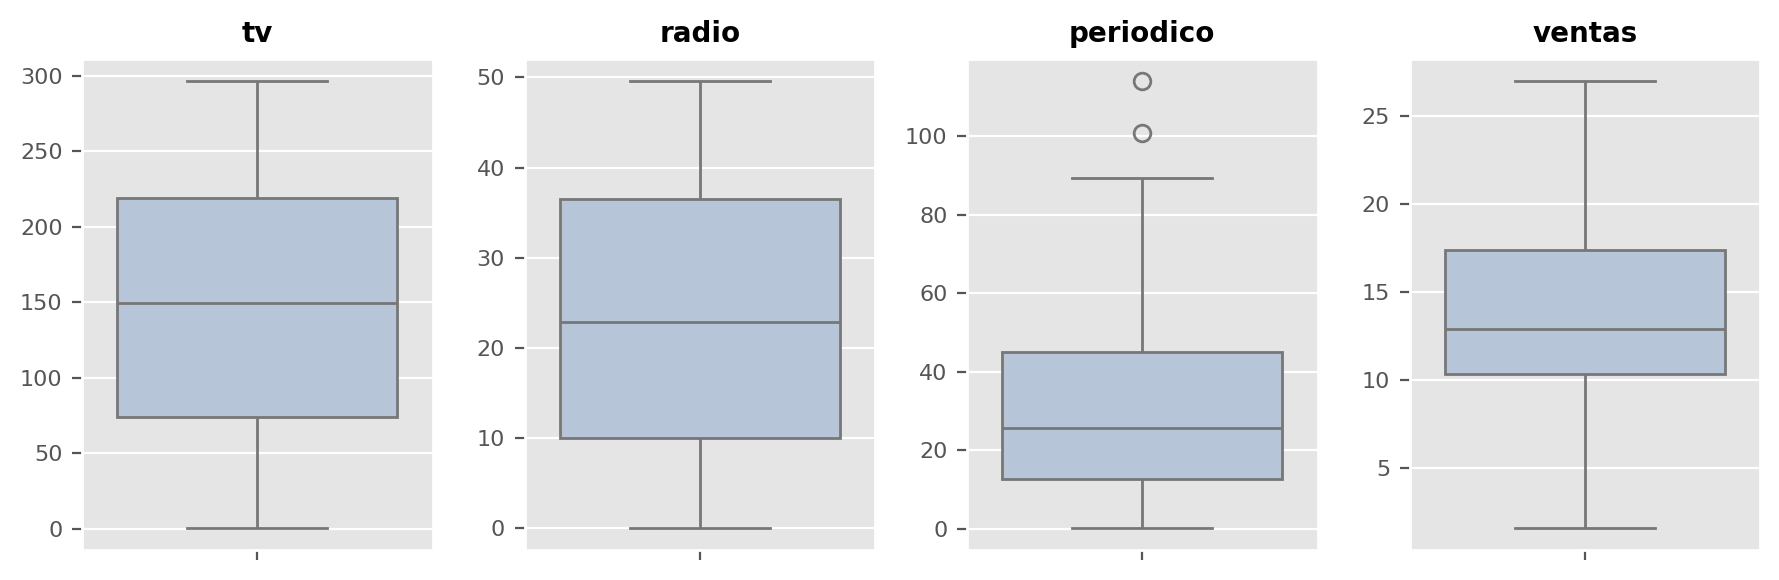

In [4]:
# Diagramas de caja de cada variable
# ==============================================================================
fig, axes = plt.subplots(nrows=1, ncols=4, figsize=(9, 3))

for i, colum in enumerate(datos.columns):
    sns.boxplot(y=datos[colum], ax=axes[i], color="lightsteelblue")
    axes[i].set_title(colum, fontsize=10, fontweight="bold")
    axes[i].set_ylabel("")
    axes[i].tick_params(labelsize=8)

fig.tight_layout()
plt.show()

#Representación gráfica


El primer paso antes de generar un modelo de regresión simple es representar los datos para poder intuir si existe una relación y cuantificar dicha relación mediante un coeficiente de correlación.

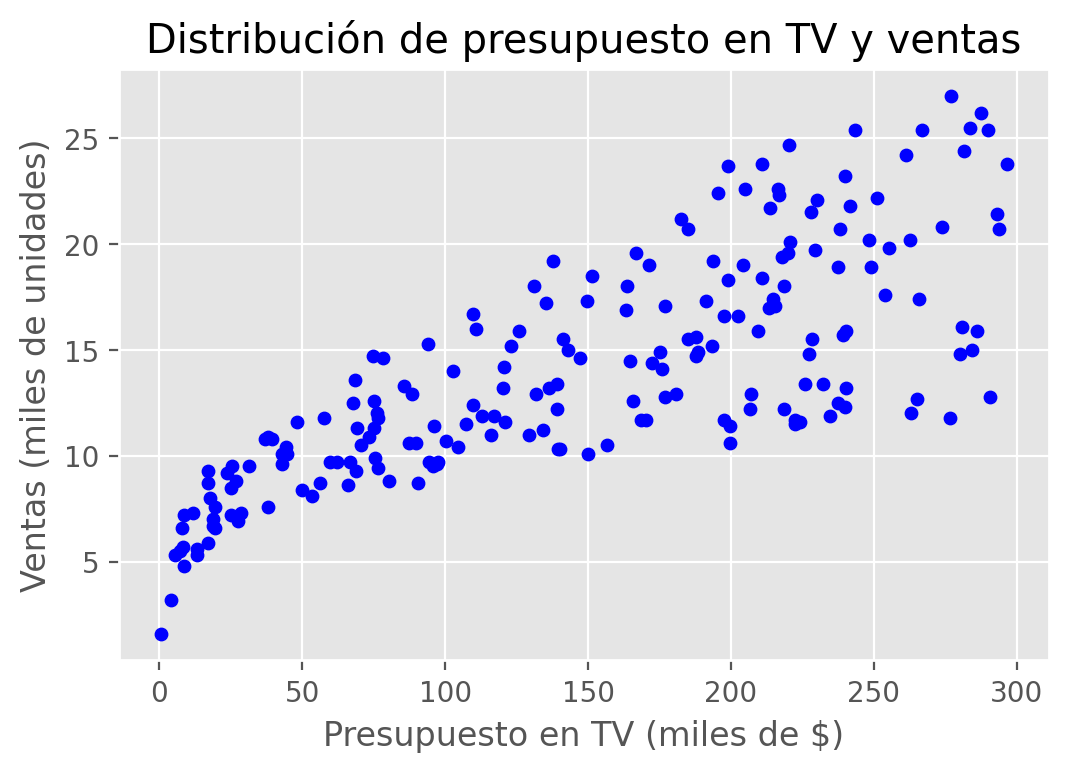

In [5]:
# Gráfico
# ==============================================================================
fig, ax = plt.subplots(figsize=(6, 3.84))

datos.plot(
    x    = 'tv',
    y    = 'ventas',
    c    = 'blue',
    kind = "scatter",
    ax   = ax
)
ax.set_xlabel('Presupuesto en TV (miles de $)')
ax.set_ylabel('Ventas (miles de unidades)')
ax.set_title('Distribución de presupuesto en TV y ventas');

In [6]:
# Correlación lineal entre las dos variables
# ==============================================================================
corr_test = pearsonr(x = datos['tv'], y =  datos['ventas'])
print("Coeficiente de correlación de Pearson: ", corr_test[0])
print("P-value: ", corr_test[1])

# ¿Qué presupuesto se relaciona más con las ventas?
# ==============================================================================
print("")
for medio in ['tv', 'radio', 'periodico']:
    r, p = pearsonr(x = datos[medio], y = datos['ventas'])
    print(f"{medio:<10} r = {r:.2f}   p-value = {p:.2e}")

Coeficiente de correlación de Pearson:  0.7822244248616067
P-value:  1.467389700194602e-42

tv         r = 0.78   p-value = 1.47e-42
radio      r = 0.58   p-value = 4.35e-19
periodico  r = 0.23   p-value = 1.15e-03


El gráfico y el test de correlación muestran una relación lineal, de intensidad alta y positiva (r = 0.78).
 De los tres medios, TV es el que más se relaciona con las ventas (radio: r = 0.58, correlación moderada; periódicos: r = 0.23, correlación baja. Tiene sentido intentar generar un modelo de regresión lineal con el objetivo de predecir las ventas en función del presupuesto en TV.


#Ajuste del modelo


Se ajusta un modelo empleando como variable respuesta `ventas` y como predictor `tv`. Como en todo estudio predictivo, no solo es importante ajustar el modelo, sino también cuantificar su capacidad para predecir nuevas observaciones. Para poder hacer esta evaluación, se dividen los datos al azar en dos grupos: uno de entrenamiento (80%, 160 mercados) y otro de test (20%, 40 mercados).

El modelo se estima por **mínimos cuadrados ordinarios (MCO)**: la "mejor" recta es la que hace mínima la suma de los errores al cuadrado.

- Residuo: $e_i = y_i - \hat{y}_i$, distancia vertical entre el dato y la recta.
- Suma de cuadrados del error: $SCE = e_1^2 + e_2^2 + ... + e_n^2$ (en inglés RSS).
- El problema: $\min \sum (y_i - \hat{y}_i)^2 = \min SCE$. Los mejores $\hat{β}_0$ y $\hat{β}_1$ son los que minimizan la SCE.

#Scikit-learn

In [8]:
# División de los datos en train y test
# ==============================================================================
X = datos[['tv']]
y = datos['ventas']
X_train, X_test, y_train, y_test = train_test_split(
                                        X.values.reshape(-1,1),
                                        y.values.reshape(-1,1),
                                        train_size   = 0.8,
                                        random_state = 1234,
                                        shuffle      = True
                                    )
print(f"Mercados en train: {len(X_train)} | Mercados en test: {len(X_test)}")

# Creación del modelo
# ==============================================================================
modelo = LinearRegression()
modelo.fit(X = X_train, y = y_train)

Mercados en train: 160 | Mercados en test: 40


LinearRegression()

In [9]:
# Información del modelo
# ==============================================================================
print("Intercept:", modelo.intercept_)
print("Coeficiente:", list(zip(X.columns, modelo.coef_.flatten(), )))
print("Coeficiente de determinación R^2 (train):", modelo.score(X_train, y_train))
print("")
print(f"Modelo estimado: ventas = {modelo.intercept_[0]:.3f} + {modelo.coef_[0][0]:.4f} · tv")

Intercept: [7.24452113]
Coeficiente: [('tv', np.float64(0.0464959224277838))]
Coeficiente de determinación R^2 (train): 0.5828065534082844

Modelo estimado: ventas = 7.245 + 0.0465 · tv


Una vez entrenado el modelo, se evalúa la capacidad predictiva empleando el conjunto de test.

In [10]:
# Error de test del modelo
# ==============================================================================
predicciones = modelo.predict(X = X_test)
print(predicciones[0:3,])

rmse = np.sqrt(mean_squared_error(
        y_true  = y_test,
        y_pred  = predicciones
       ))
print("")
print(f"El error (rmse) de test es: {rmse}")

[[15.4742994 ]
 [14.20961031]
 [12.49391077]]

El error (rmse) de test es: 3.035025655113521


#Statsmodels
La implementación de regresión lineal de Statsmodels, es más completa que la de Scikitlearn ya que, además de ajustar el modelo, permite calcular los test estadísticos y análisis necesarios para verificar que se cumplen las condiciones sobre las que se basa este tipo de modelos. Statsmodels tiene dos formas de entrenar el modelo:

- Indicando la fórmula del modelo y pasando los datos de entrenamiento como un dataframe que incluye la variable respuesta y los predictores. Esta forma es similar a la utilizada en R.

- Pasar dos matrices, una con los predictores y otra con la variable respuesta. Esta es igual a la empleada por Scikitlearn con la diferencia de que a la matriz de predictores hay que añadirle una primera columna de unos.

In [11]:
# División de los datos en train y test
# ==============================================================================
X = datos[['tv']]
y = datos['ventas']

X_train, X_test, y_train, y_test = train_test_split(
                                        X.values.reshape(-1,1),
                                        y.values.reshape(-1,1),
                                        train_size   = 0.8,
                                        random_state = 1234,
                                        shuffle      = True
                                    )

In [ ]:
# Creación del modelo utilizando el modo fórmula (similar a R)
# ==============================================================================
# datos_train = pd.DataFrame(np.hstack((X_train, y_train)), columns=['tv', 'ventas'])
# modelo = smf.ols(formula = 'ventas ~ tv', data = datos_train)
# modelo = modelo.fit()
# print(modelo.summary())

In [12]:
# Creación del modelo utilizando matrices como en scikitlearn
# ==============================================================================
# A la matriz de predictores se le tiene que añadir una columna de 1s para el intercept del modelo
X_train = sm.add_constant(X_train, prepend=True)
modelo = sm.OLS(endog=y_train, exog=X_train)
modelo = modelo.fit()
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.583
Model:                            OLS   Adj. R-squared:                  0.580
Method:                 Least Squares   F-statistic:                     220.7
Date:                Wed, 04 Nov 2026   Prob (F-statistic):           8.39e-32
Time:                        17:17:16   Log-Likelihood:                -417.78
No. Observations:                 160   AIC:                             839.6
Df Residuals:                     158   BIC:                             845.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.2445      0.527     13.734      0.0

#Intervalos de confianza de los coeficientes


El **error estándar (SE)** refleja cuánto variaría el estimador si repitiéramos la estimación con otra muestra. Depende de la varianza del error $σ^2$ y de la dispersión de $X$. Con él se construye el intervalo de confianza al 95%:

$$\hat{β}_1 ± 1.96 \cdot SE(\hat{β}_1)$$

**Cómo se lee:** tenemos un 95% de confianza de que el verdadero $β_1$ está dentro del intervalo.

In [13]:
# Intervalos de confianza para los coeficientes del modelo
# ==============================================================================
modelo.conf_int(alpha=0.05)

array([[6.20267527, 8.28636698],
       [0.04031462, 0.05267723]])

#Prueba de hipótesis para $β_1$


¿Existe realmente una relación lineal entre el presupuesto en TV y las ventas?

- $H_0: β_1 = 0$ → no hay relación lineal (el modelo queda $Y = β_0 + ϵ$).
- $H_1: β_1 \neq 0$ → hay relación lineal.

El estadístico es $t = \hat{β}_1 / SE(\hat{β}_1)$. Si está muy lejos de 0, es improbable que $H_0$ sea cierta.

**Ojo:** significativo no es lo mismo que causal ni que importante para el negocio; la magnitud la da el coeficiente.

In [14]:
# Estadístico t y p-value de la pendiente (cálculo manual)
# ==============================================================================
beta_1    = modelo.params[1]
se_beta_1 = modelo.bse[1]
t_stat    = beta_1 / se_beta_1
print(f"β1 = {beta_1:.4f} | SE(β1) = {se_beta_1:.4f}")
print(f"t = β1 / SE(β1) = {t_stat:.2f}")
print(f"p-value = {modelo.pvalues[1]:.2e}")
print(f"IC 95% aproximado (β1 ± 1.96·SE): [{beta_1 - 1.96*se_beta_1:.4f} ; {beta_1 + 1.96*se_beta_1:.4f}]")

β1 = 0.0465 | SE(β1) = 0.0031
t = β1 / SE(β1) = 14.86
p-value = 8.39e-32
IC 95% aproximado (β1 ± 1.96·SE): [0.0404 ; 0.0526]


#Medidas de bondad de ajuste: CME, RCME, RSE y $R^2$


¿Qué tan bien ajusta la recta a los datos? Cuatro medidas complementarias:

| Medida | Fórmula | Interpretación |
|---|---|---|
| CME (ECM, en inglés MSE) | $CME = \frac{1}{n}\sum (y_i - \hat{y}_i)^2$ | Promedio de los errores al cuadrado. Está en unidades². |
| RCME (en inglés RMSE) | $RCME = \sqrt{CME}$ | Error promedio en las unidades de $Y$. Sirve para comparar modelos sobre los mismos datos. |
| RSE | $RSE = \sqrt{SCE / (n-2)}$ | Error estándar residual: divide por los grados de libertad. |
| $R^2$ | $R^2 = 1 - SCE / STC$ | Proporción de la variabilidad de $Y$ que explica el modelo. Entre 0 y 1. |

**Regla:** CME, RCME y RSE, cuanto más bajos mejor. $R^2$, cuanto más alto mejor.

In [ ]:
# Medidas de bondad de ajuste en los datos de entrenamiento
# ==============================================================================
y_real = y_train.flatten()
y_pred = modelo.predict(exog = X_train)
n      = len(y_real)

sce  = np.sum((y_real - y_pred)**2)              # Suma de cuadrados del error
stc  = np.sum((y_real - y_real.mean())**2)       # Suma total de cuadrados
cme  = sce / n
rcme = np.sqrt(cme)
rse  = np.sqrt(sce / (n - 2))
r2   = 1 - sce / stc

print(f"CME  = {cme:.3f}")
print(f"RCME = {rcme:.3f}")
print(f"RSE  = {rse:.3f}")
print(f"R²   = {r2:.3f}")

CME  = 10.852
RCME = 3.294
RSE  = 3.315
R²   = 0.583


#Predicciones


Una vez entrenado el modelo, se pueden obtener predicciones para nuevos datos. Los modelos de statsmodels permiten calcular las predicciones de dos formas:

- `.predict()`: devuelve únicamente el valor de las predicciones.

- `.get_prediction().summary_frame()`: devuelve, además de las predicciones, los intervalos de confianza asociados.

In [ ]:
# Predicciones con intervalo de confianza del 95%
# ==============================================================================
predicciones = modelo.get_prediction(exog = X_train).summary_frame(alpha=0.05)
predicciones.head(4)

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,18.408192,0.393588,17.630820,19.185564,11.814662,25.001722
1,11.763925,0.303763,11.163965,12.363885,5.188951,18.338899
2,16.864527,0.323552,16.225482,17.503573,10.285872,23.443183
3,13.530770,0.264360,13.008635,14.052904,6.962440,20.099100


#Representación gráfica del modelo


Además de la línea de mínimos cuadrados, es recomendable incluir los límites superior e inferior del intervalo de confianza. Esto permite identificar la región en la que, según el modelo generado y para un determinado nivel de confianza, se encuentra el valor promedio de la variable respuesta.

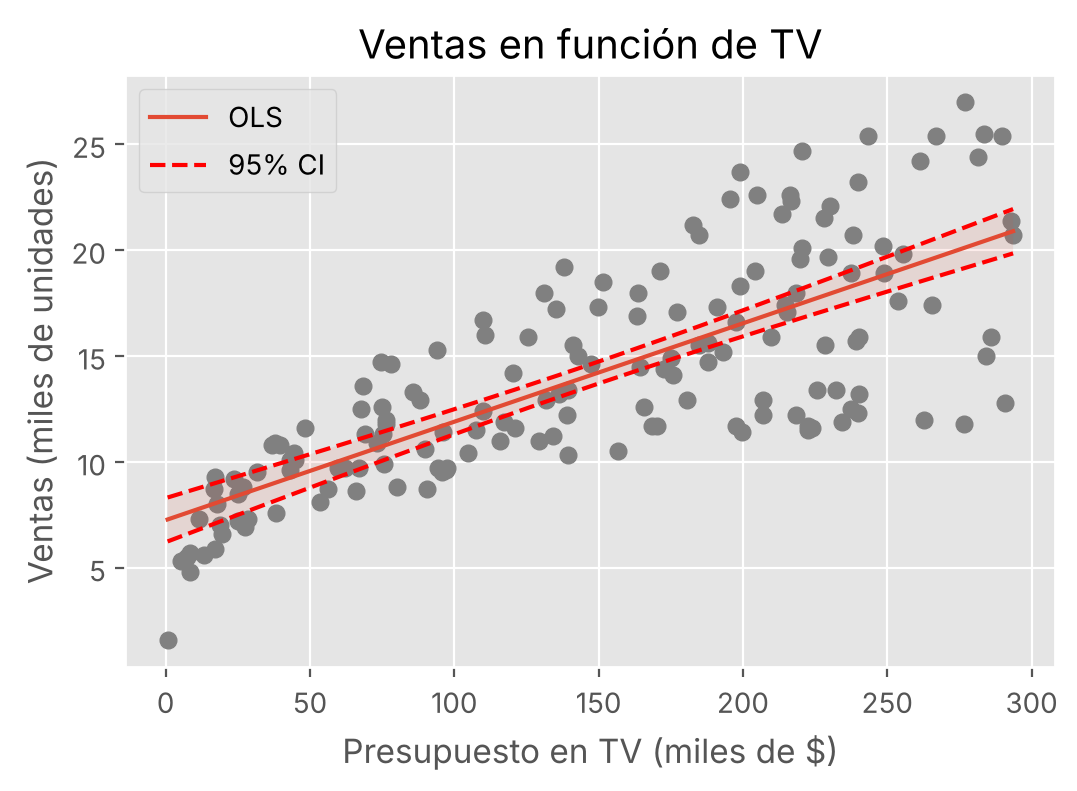

In [ ]:
# Predicciones con intervalo de confianza del 95%
# ==============================================================================
predicciones = modelo.get_prediction(exog=X_train).summary_frame(alpha=0.05)
predicciones['x'] = X_train[:, 1]
predicciones['y'] = y_train
predicciones = predicciones.sort_values('x')

# Gráfico del modelo
# ==============================================================================
plt.figure(figsize=(6, 3.84))

plt.scatter(predicciones['x'], predicciones['y'], marker='o', color="gray")
plt.plot(predicciones['x'], predicciones["mean"], linestyle='-', label="OLS")
plt.plot(predicciones['x'], predicciones["mean_ci_lower"], linestyle='--', color='red', label="95% CI")
plt.plot(predicciones['x'], predicciones["mean_ci_upper"], linestyle='--', color='red')
plt.fill_between(predicciones['x'], predicciones["mean_ci_lower"], predicciones["mean_ci_upper"], alpha=0.1)
plt.xlabel('Presupuesto en TV (miles de $)')
plt.ylabel('Ventas (miles de unidades)')
plt.title('Ventas en función de TV')
plt.legend()

plt.show()

#Error de test


**Train vs. test: ¿hay sobreajuste?** La prueba de fuego es medir el error en los datos que el modelo no vio.

In [ ]:
# Error de test del modelo
# ==============================================================================
X_test = sm.add_constant(X_test, prepend=True)
predicciones = modelo.predict(exog = X_test)
rmse = np.sqrt(mean_squared_error(
        y_true  = y_test,
        y_pred  = predicciones
       ))
print("")
print(f"El error (rmse) de test es: {rmse}")

# Comparación con el error de entrenamiento
# ==============================================================================
rmse_train = np.sqrt(mean_squared_error(
        y_true  = y_train,
        y_pred  = modelo.predict(exog = X_train)
       ))
print(f"RCME train = {rmse_train:.2f} · RCME test = {rmse:.2f}")


El error (rmse) de test es: 3.035025655113521
RCME train = 3.29 · RCME test = 3.04



#Interpretación


La columna (coef) devuelve el valor estimado para los dos parámetros de la ecuación del modelo lineal ( $\hat{β}_0$  y $\hat{β}_1$ ) que equivalen a la ordenada en el origen (intercept o const) y a la pendiente. Se muestran también los errores estándar, el valor del estadístico t y el p-value (dos colas) de cada uno de los dos parámetros. Esto permite determinar si los predictores son significativamente distintos de 0, es decir, que tienen importancia en el modelo. Para el modelo generado, tanto la ordenada en el origen como la pendiente son significativas (p-values < 0.05).

El modelo lineal generado (ajustado con los 160 mercados de entrenamiento) sigue la ecuación:
$$
ventas = 7.245 + 0.0465 \cdot tv
$$

- $\hat{β}_0 = 7.245$: ventas esperadas sin publicidad en TV, unas 7.245 mil unidades.
- $\hat{β}_1 = 0.0465$: por cada \$1.000 más en TV, las ventas aumentan en promedio unas 46 unidades.

**Precisión de los estimadores:**

| Parámetro | Estimación | SE | IC 95% |
|---|---|---|---|
| $β_0$ (intercepto) | 7.245 | 0.527 | [6.20 ; 8.29] |
| $β_1$ (TV) | 0.0465 | 0.0031 | [0.0403 ; 0.0527] |

Cada \$1.000 en TV aporta entre 40 y 53 unidades más. El intervalo no incluye el 0.

**Prueba de hipótesis:** $t = 0.0465 / 0.0031 ≈ 14.9$, con p-value ≈ 8.4e-32 < 0.05, por lo que se rechaza $H_0$: hay relación lineal entre las ventas y el presupuesto en TV.

**Bondad de ajuste:**

- $R^2 = 0.583$: cerca del 58% de la variabilidad de las ventas se explica por el presupuesto en TV. El p-value del test F (`Prob (F-statistic) = 8.39e-32`) indica que el modelo explica más varianza de la esperada por azar.
- $RSE = 3.32$: las ventas observadas se desvían de la recta en promedio unas 3.300 unidades.

**Train vs. test:** RCME train = 3.29 · RCME test = 3.04. El error con datos nuevos no empeora, así que **no hay sobreajuste**. Un modelo de una variable difícilmente memoriza ruido; con modelos más flexibles esta comparación será clave.


**¿Y el otro 40%?** Lo explican otros factores: radio, periódicos, precio, competencia, estacionalidad... Si agregamos radio al modelo, ¿qué esperan que pase con el $R^2$?


#Ejemplo regresión lineal múltiple


Se continúa con el **caso de la Clase 15**. El modelo simple con TV explica cerca del 60% de la variabilidad de las ventas. ¿Y el otro 40%? Lo explican otros factores: radio, periódicos, precio, competencia, estacionalidad, etc.

Varias variables explican mejor que una. Se parte de un modelo con los tres medios y se evalúa cuáles aportan:

$$ventas = β_0 + β_1 \cdot tv + β_2 \cdot radio + β_3 \cdot periodico + ϵ$$

En la regresión múltiple **cada coeficiente se lee "manteniendo lo demás constante"**.


#Librerías


Las librerías utilizadas en este ejemplo son:

In [ ]:
# Tratamiento de datos
# ==============================================================================
import pandas as pd
import numpy as np

# Gráficos
# ==============================================================================
import matplotlib.pyplot as plt
from matplotlib import style
import seaborn as sns

# Preprocesado y modelado
# ==============================================================================
from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from scipy import stats

# Configuración matplotlib
# ==============================================================================
plt.rcParams['image.cmap'] = "bwr"
#plt.rcParams['figure.dpi'] = "100"
plt.rcParams['savefig.bbox'] = "tight"
style.use('ggplot') or plt.style.use('ggplot')

# Configuración warnings
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')

#Datos

El objetivo es predecir las ventas (miles de unidades) en función de la inversión (miles de $) en tres canales de publicidad: tv, radio y periódicos. Son los mismos 200 mercados del ejemplo simple.

In [ ]:
# Datos
# ==============================================================================
tv = [230.1, 44.5, 17.2, 151.5, 180.8, 8.7, 57.5, 120.2, 8.6, 199.8, 66.1, 214.7,
      23.8, 97.5, 204.1, 195.4, 67.8, 281.4, 69.2, 147.3, 218.4, 237.4, 13.2,
      228.3, 62.3, 262.9, 142.9, 240.1, 248.8, 70.6, 292.9, 112.9, 97.2, 265.6,
      95.7, 290.7, 266.9, 74.7, 43.1, 228.0, 202.5, 177.0, 293.6, 206.9, 25.1,
      175.1, 89.7, 239.9, 227.2, 66.9, 199.8, 100.4, 216.4, 182.6, 262.7, 198.9,
      7.3, 136.2, 210.8, 210.7, 53.5, 261.3, 239.3, 102.7, 131.1, 69.0, 31.5,
      139.3, 237.4, 216.8, 199.1, 109.8, 26.8, 129.4, 213.4, 16.9, 27.5, 120.5,
      5.4, 116.0, 76.4, 239.8, 75.3, 68.4, 213.5, 193.2, 76.3, 110.7, 88.3, 109.8,
      134.3, 28.6, 217.7, 250.9, 107.4, 163.3, 197.6, 184.9, 289.7, 135.2, 222.4,
      296.4, 280.2, 187.9, 238.2, 137.9, 25.0, 90.4, 13.1, 255.4, 225.8, 241.7, 175.7,
      209.6, 78.2, 75.1, 139.2, 76.4, 125.7, 19.4, 141.3, 18.8, 224.0, 123.1, 229.5,
      87.2, 7.8, 80.2, 220.3, 59.6, 0.7, 265.2, 8.4, 219.8, 36.9, 48.3, 25.6, 273.7,
      43.0, 184.9, 73.4, 193.7, 220.5, 104.6, 96.2, 140.3, 240.1, 243.2, 38.0, 44.7,
      280.7, 121.0, 197.6, 171.3, 187.8, 4.1, 93.9, 149.8, 11.7, 131.7, 172.5, 85.7,
      188.4, 163.5, 117.2, 234.5, 17.9, 206.8, 215.4, 284.3, 50.0, 164.5, 19.6, 168.4,
      222.4, 276.9, 248.4, 170.2, 276.7, 165.6, 156.6, 218.5, 56.2, 287.6, 253.8, 205.0,
      139.5, 191.1, 286.0, 18.7, 39.5, 75.5, 17.2, 166.8, 149.7, 38.2, 94.2, 177.0,
      283.6, 232.1]

radio = [37.8, 39.3, 45.9, 41.3, 10.8, 48.9, 32.8, 19.6, 2.1, 2.6, 5.8, 24.0, 35.1,
         7.6, 32.9, 47.7, 36.6, 39.6, 20.5, 23.9, 27.7, 5.1, 15.9, 16.9, 12.6, 3.5,
         29.3, 16.7, 27.1, 16.0, 28.3, 17.4, 1.5, 20.0, 1.4, 4.1, 43.8, 49.4, 26.7,
         37.7, 22.3, 33.4, 27.7, 8.4, 25.7, 22.5, 9.9, 41.5, 15.8, 11.7, 3.1, 9.6,
         41.7, 46.2, 28.8, 49.4, 28.1, 19.2, 49.6, 29.5, 2.0, 42.7, 15.5, 29.6, 42.8,
         9.3, 24.6, 14.5, 27.5, 43.9, 30.6, 14.3, 33.0, 5.7, 24.6, 43.7, 1.6, 28.5,
         29.9, 7.7, 26.7, 4.1, 20.3, 44.5, 43.0, 18.4, 27.5, 40.6, 25.5, 47.8, 4.9,
         1.5, 33.5, 36.5, 14.0, 31.6, 3.5, 21.0, 42.3, 41.7, 4.3, 36.3, 10.1, 17.2,
         34.3, 46.4, 11.0, 0.3, 0.4, 26.9, 8.2, 38.0, 15.4, 20.6, 46.8, 35.0, 14.3,
         0.8, 36.9, 16.0, 26.8, 21.7, 2.4, 34.6, 32.3, 11.8, 38.9, 0.0, 49.0, 12.0,
         39.6, 2.9, 27.2, 33.5, 38.6, 47.0, 39.0, 28.9, 25.9, 43.9, 17.0, 35.4, 33.2,
         5.7, 14.8, 1.9, 7.3, 49.0, 40.3, 25.8, 13.9, 8.4, 23.3, 39.7, 21.1, 11.6, 43.5,
         1.3, 36.9, 18.4, 18.1, 35.8, 18.1, 36.8, 14.7, 3.4, 37.6, 5.2, 23.6, 10.6, 11.6,
         20.9, 20.1, 7.1, 3.4, 48.9, 30.2, 7.8, 2.3, 10.0, 2.6, 5.4, 5.7, 43.0, 21.3, 45.1,
         2.1, 28.7, 13.9, 12.1, 41.1, 10.8, 4.1, 42.0, 35.6, 3.7, 4.9, 9.3, 42.0, 8.6]

periodico = [69.2, 45.1, 69.3, 58.5, 58.4, 75.0, 23.5, 11.6, 1.0, 21.2, 24.2, 4.0,
             65.9, 7.2, 46.0, 52.9, 114.0, 55.8, 18.3, 19.1, 53.4, 23.5, 49.6, 26.2,
             18.3, 19.5, 12.6, 22.9, 22.9, 40.8, 43.2, 38.6, 30.0, 0.3, 7.4, 8.5, 5.0,
             45.7, 35.1, 32.0, 31.6, 38.7, 1.8, 26.4, 43.3, 31.5, 35.7, 18.5, 49.9,
             36.8, 34.6, 3.6, 39.6, 58.7, 15.9, 60.0, 41.4, 16.6, 37.7, 9.3, 21.4, 54.7,
             27.3, 8.4, 28.9, 0.9, 2.2, 10.2, 11.0, 27.2, 38.7, 31.7, 19.3, 31.3, 13.1,
             89.4, 20.7, 14.2, 9.4, 23.1, 22.3, 36.9, 32.5, 35.6, 33.8, 65.7, 16.0, 63.2,
             73.4, 51.4, 9.3, 33.0, 59.0, 72.3, 10.9, 52.9, 5.9, 22.0, 51.2, 45.9, 49.8,
             100.9, 21.4, 17.9, 5.3, 59.0, 29.7, 23.2, 25.6, 5.5, 56.5, 23.2, 2.4, 10.7,
             34.5, 52.7, 25.6, 14.8, 79.2, 22.3, 46.2, 50.4, 15.6, 12.4, 74.2, 25.9, 50.6,
             9.2, 3.2, 43.1, 8.7, 43.0, 2.1, 45.1, 65.6, 8.5, 9.3, 59.7, 20.5, 1.7, 12.9,
             75.6, 37.9, 34.4, 38.9, 9.0, 8.7, 44.3, 11.9, 20.6, 37.0, 48.7, 14.2, 37.7,
             9.5, 5.7, 50.5, 24.3, 45.2, 34.6, 30.7, 49.3, 25.6, 7.4, 5.4, 84.8, 21.6, 19.4,
             57.6, 6.4, 18.4, 47.4, 17.0, 12.8, 13.1, 41.8, 20.3, 35.2, 23.7, 17.6, 8.3,
             27.4, 29.7, 71.8, 30.0, 19.6, 26.6, 18.2, 3.7, 23.4, 5.8, 6.0, 31.6, 3.6, 6.0,
             13.8, 8.1, 6.4, 66.2, 8.7]

ventas = [22.1, 10.4, 9.3, 18.5, 12.9, 7.2, 11.8, 13.2, 4.8, 10.6, 8.6, 17.4, 9.2, 9.7,
          19.0, 22.4, 12.5, 24.4, 11.3, 14.6, 18.0, 12.5, 5.6, 15.5, 9.7, 12.0, 15.0, 15.9,
          18.9, 10.5, 21.4, 11.9, 9.6, 17.4, 9.5, 12.8, 25.4, 14.7, 10.1, 21.5, 16.6, 17.1,
          20.7, 12.9, 8.5, 14.9, 10.6, 23.2, 14.8, 9.7, 11.4, 10.7, 22.6, 21.2, 20.2, 23.7,
          5.5, 13.2, 23.8, 18.4, 8.1, 24.2, 15.7, 14.0, 18.0, 9.3, 9.5, 13.4, 18.9, 22.3,
          18.3, 12.4, 8.8, 11.0, 17.0, 8.7, 6.9, 14.2, 5.3, 11.0, 11.8, 12.3, 11.3, 13.6,
          21.7, 15.2, 12.0, 16.0, 12.9, 16.7, 11.2, 7.3, 19.4, 22.2, 11.5, 16.9, 11.7, 15.5,
          25.4, 17.2, 11.7, 23.8, 14.8, 14.7, 20.7, 19.2, 7.2, 8.7, 5.3, 19.8, 13.4, 21.8,
          14.1, 15.9, 14.6, 12.6, 12.2, 9.4, 15.9, 6.6, 15.5, 7.0, 11.6, 15.2, 19.7, 10.6,
          6.6, 8.8, 24.7, 9.7, 1.6, 12.7, 5.7, 19.6, 10.8, 11.6, 9.5, 20.8, 9.6, 20.7, 10.9,
          19.2, 20.1, 10.4, 11.4, 10.3, 13.2, 25.4, 10.9, 10.1, 16.1, 11.6, 16.6, 19.0, 15.6,
          3.2, 15.3, 10.1, 7.3, 12.9, 14.4, 13.3, 14.9, 18.0, 11.9, 11.9, 8.0, 12.2, 17.1,
          15.0, 8.4, 14.5, 7.6, 11.7, 11.5, 27.0, 20.2, 11.7, 11.8, 12.6, 10.5, 12.2, 8.7,
          26.2, 17.6, 22.6, 10.3, 17.3, 15.9, 6.7, 10.8, 9.9, 5.9, 19.6, 17.3, 7.6, 9.7, 12.8,
          25.5, 13.4]

datos = pd.DataFrame({'tv': tv, 'radio': radio, 'periodico':periodico, 'ventas': ventas})

#Relación entre variables


El primer paso a la hora de establecer un modelo lineal múltiple es estudiar la relación que existe entre variables. Esta información es crítica a la hora de identificar cuáles pueden ser los mejores predictores para el modelo, y para detectar colinealidad entre predictores. A modo complementario, es recomendable representar la distribución de cada variable mediante histogramas.

In [ ]:
# Correlación entre columnas numéricas
# ==============================================================================

def tidy_corr_matrix(corr_mat):
    '''
    Función para convertir una matriz de correlación de pandas en formato tidy
    tidy format: en cada línea figuran 2 variables y su correlación
    (se evitan las correlaciones 1 de una variable con si misma)
    '''
    corr_mat = corr_mat.stack().reset_index()
    corr_mat.columns = ['variable_1','variable_2','r']
    corr_mat = corr_mat.loc[corr_mat['variable_1'] != corr_mat['variable_2'], :]
    corr_mat['abs_r'] = np.abs(corr_mat['r'])
    corr_mat = corr_mat.sort_values('abs_r', ascending=False)

    return(corr_mat)



corr_matrix = datos.select_dtypes(include=['float64', 'int']).corr(method='pearson')
tidy_corr_matrix(corr_matrix).head(10)

,variable_1,variable_2,r,abs_r
3,tv,ventas,0.782224,0.782224
12,ventas,tv,0.782224,0.782224
7,radio,ventas,0.576223,0.576223
13,ventas,radio,0.576223,0.576223
9,periodico,radio,0.354104,0.354104
6,radio,periodico,0.354104,0.354104
14,ventas,periodico,0.228299,0.228299
11,periodico,ventas,0.228299,0.228299
2,tv,periodico,0.056648,0.056648
8,periodico,tv,0.056648,0.056648


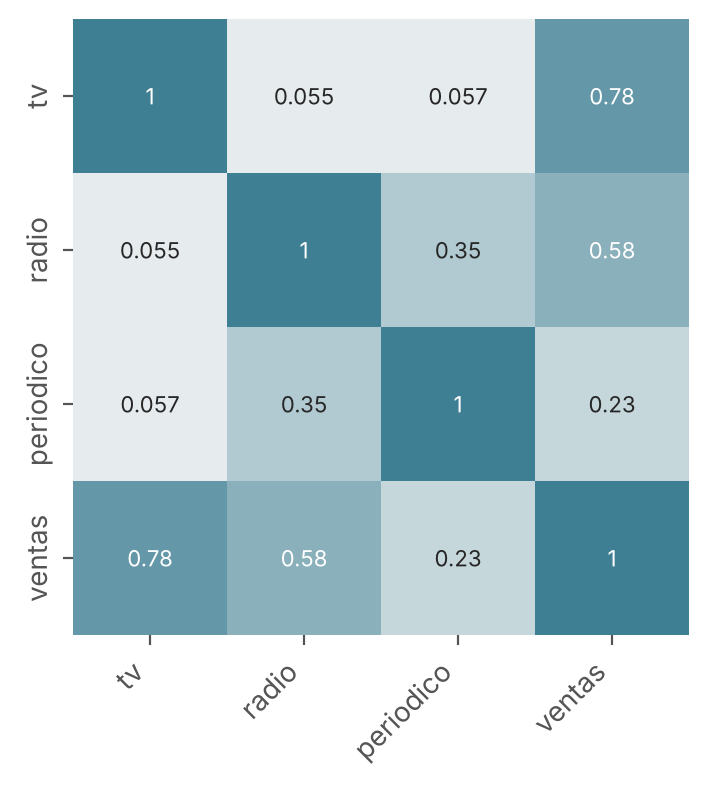

In [ ]:
# Heatmap matriz de correlaciones
# ==============================================================================
plt.figure(figsize=(4, 4))

sns.heatmap(
    corr_matrix,
    annot=True,
    cbar=False,
    annot_kws={"size": 8},
    vmin=-1,
    vmax=1,
    center=0,
    cmap=sns.diverging_palette(20, 220, n=200),
    square=True
)

plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.show()

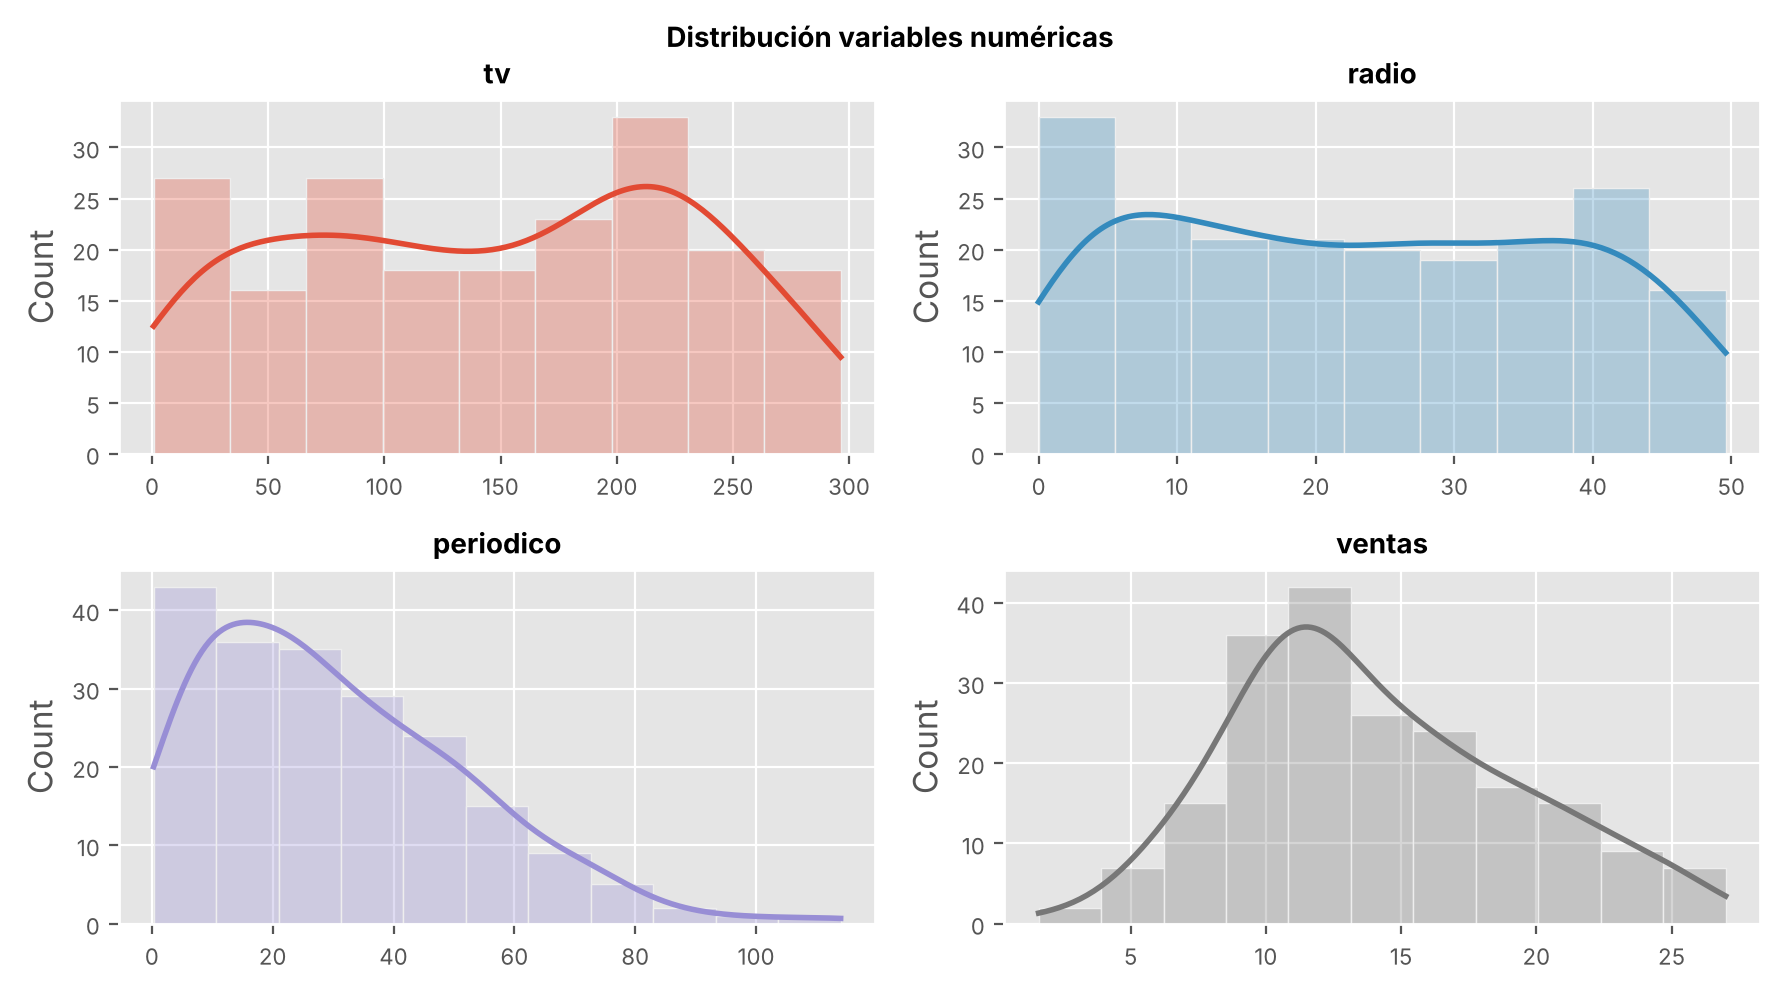

In [ ]:
# Gráfico de distribución para cada variable numérica
# ==============================================================================
# Ajustar número de subplots en función del número de columnas
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(9, 5))
axes = axes.flat
columnas_numeric = datos.select_dtypes(include=['float64', 'int']).columns

for i, colum in enumerate(columnas_numeric):
    sns.histplot(
        data    = datos,
        x       = colum,
        stat    = "count",
        kde     = True,
        color   = (list(plt.rcParams['axes.prop_cycle'])*2)[i]["color"],
        line_kws= {'linewidth': 2},
        alpha   = 0.3,
        ax      = axes[i]
    )
    axes[i].set_title(colum, fontsize = 10, fontweight = "bold")
    axes[i].tick_params(labelsize = 8)
    axes[i].set_xlabel("")



fig.tight_layout()
plt.subplots_adjust(top = 0.9)
fig.suptitle('Distribución variables numéricas', fontsize = 10, fontweight = "bold");

##Ajuste del modelo


Se ajusta un modelo lineal múltiple con el objetivo de predecir las ventas en función de la inversión en los tres canales de publicidad.

In [ ]:
# División de los datos en train y test
# ==============================================================================
X = datos[['tv', 'radio', 'periodico']]
y = datos['ventas']

X_train, X_test, y_train, y_test = train_test_split(
                                        X,
                                        y.values.reshape(-1,1),
                                        train_size   = 0.8,
                                        random_state = 1234,
                                        shuffle      = True
)

In [ ]:
# Creación del modelo utilizando el modo fórmula (similar a R)
# ==============================================================================
# datos_train = pd.DataFrame(
#                     np.hstack((X_train, y_train)),
#                     columns=['tv', 'radio', 'periodico', 'ventas']
#               )
# modelo = smf.ols(formula = 'ventas ~ tv + radio + periodico', data = datos_train)
# modelo = modelo.fit()
# print(modelo.summary())

In [ ]:
# Creación del modelo utilizando matrices como en scikitlearn
# ==============================================================================
# A la matriz de predictores se le tiene que añadir una columna de 1s para el intercept del modelo
X_train = sm.add_constant(X_train, prepend=True)
modelo = sm.OLS(endog=y_train, exog=X_train)
modelo = modelo.fit()
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.894
Model:                            OLS   Adj. R-squared:                  0.892
Method:                 Least Squares   F-statistic:                     437.8
Date:                Wed, 04 Nov 2026   Prob (F-statistic):           1.01e-75
Time:                        13:11:59   Log-Likelihood:                -308.29
No. Observations:                 160   AIC:                             624.6
Df Residuals:                     156   BIC:                             636.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.8497      0.365      7.803      0.0


El modelo con todas las variables introducidas como predictores tiene un  $R^2$  alto (0.894), es capaz de explicar el 89.4% de la variabilidad observada en las ventas. El p-value del modelo es significativo (1.01e-75) por lo que se puede aceptar que el modelo es mejor que lo esperado por azar: al menos uno de los coeficientes parciales de regresión es distinto de 0.

Acorde al p-value obtenido para el coeficiente parcial de regresión de `periodico` (0.723), esta variable no contribuye de forma significativa al modelo (su IC 95% [-0.011 ; 0.016] incluye el 0). Esto coincide con lo visto en la exploración: periódicos tenía una correlación baja con las ventas (r = 0.23). Se entrena de nuevo el modelo, pero esta vez excluyendo el predictor `periodico`, es decir, **agregando solo radio** al modelo simple de TV, como en la Clase 15:

$$ventas = β_0 + β_1 \cdot tv + β_2 \cdot radio + ϵ$$


In [ ]:
# Creación del modelo utilizando matrices
# ==============================================================================
# Se elimina la columna periodico del conjunto de train y test
X_train = X_train.drop(columns = 'periodico')
X_test  = X_test.drop(columns = 'periodico')

# A la matriz de predictores se le tiene que añadir una columna de 1s para el
# intercept del modelo
X_train = sm.add_constant(X_train, prepend=True)
modelo  = sm.OLS(endog=y_train, exog=X_train,)
modelo  = modelo.fit()
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.894
Model:                            OLS   Adj. R-squared:                  0.892
Method:                 Least Squares   F-statistic:                     660.3
Date:                Wed, 04 Nov 2026   Prob (F-statistic):           3.69e-77
Time:                        13:11:59   Log-Likelihood:                -308.36
No. Observations:                 160   AIC:                             622.7
Df Residuals:                     157   BIC:                             631.9
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.9004      0.335      8.652      0.0


##Interpretación: agregamos radio


El modelo lineal múltiple generado sigue la ecuación:
$$
ventas = 2.900 + 0.0456 \cdot tv + 0.1904 \cdot radio
$$

Cada coeficiente se lee **"manteniendo lo demás constante"**:

| TV | Radio | $R^2$ |
|---|---|---|
| $β_1 = 0.0456$ | $β_2 = 0.1904$ | 0.894 |
| Por cada \$1.000 en TV, +46 unidades, con radio fijo. | El medio de mayor efecto por peso invertido: +190 unidades por \$1.000, con TV fijo. | El modelo explica el 89.4% de la variabilidad de las ventas. |

**Respuesta a la pregunta de la clase:** al agregar radio, el $R^2$ pasa de 0.583 (solo TV) a 0.894. Varias variables explican mejor que una. Además, el error de test baja de RCME ≈ 3.04 (solo TV) a RCME ≈ 1.70 (TV + radio), como se verá más abajo.

**Para el plan de marketing:** TV y radio tienen efecto significativo sobre las ventas; periódicos no aporta una vez que se consideran los otros dos medios. Por cada peso, radio es el medio de mayor efecto.


##Intervalos de confianza de los coeficientes

In [ ]:
# Intervalos de confianza para los coeficientes del modelo
# ==============================================================================
intervalos_ci = modelo.conf_int(alpha=0.05)
intervalos_ci.columns = ['2.5%', '97.5%']
intervalos_ci

,2.5%,97.5%
const,2.238211,3.562549
tv,0.042439,0.048701
radio,0.172853,0.207942


##Diagnóstico de los resíduos

In [ ]:
# Diagnóstico errores (residuos) de las predicciones de entrenamiento
# ==============================================================================
y_train = y_train.flatten()
prediccion_train = modelo.predict(exog = X_train)
residuos_train   = prediccion_train - y_train

###Inspección visual

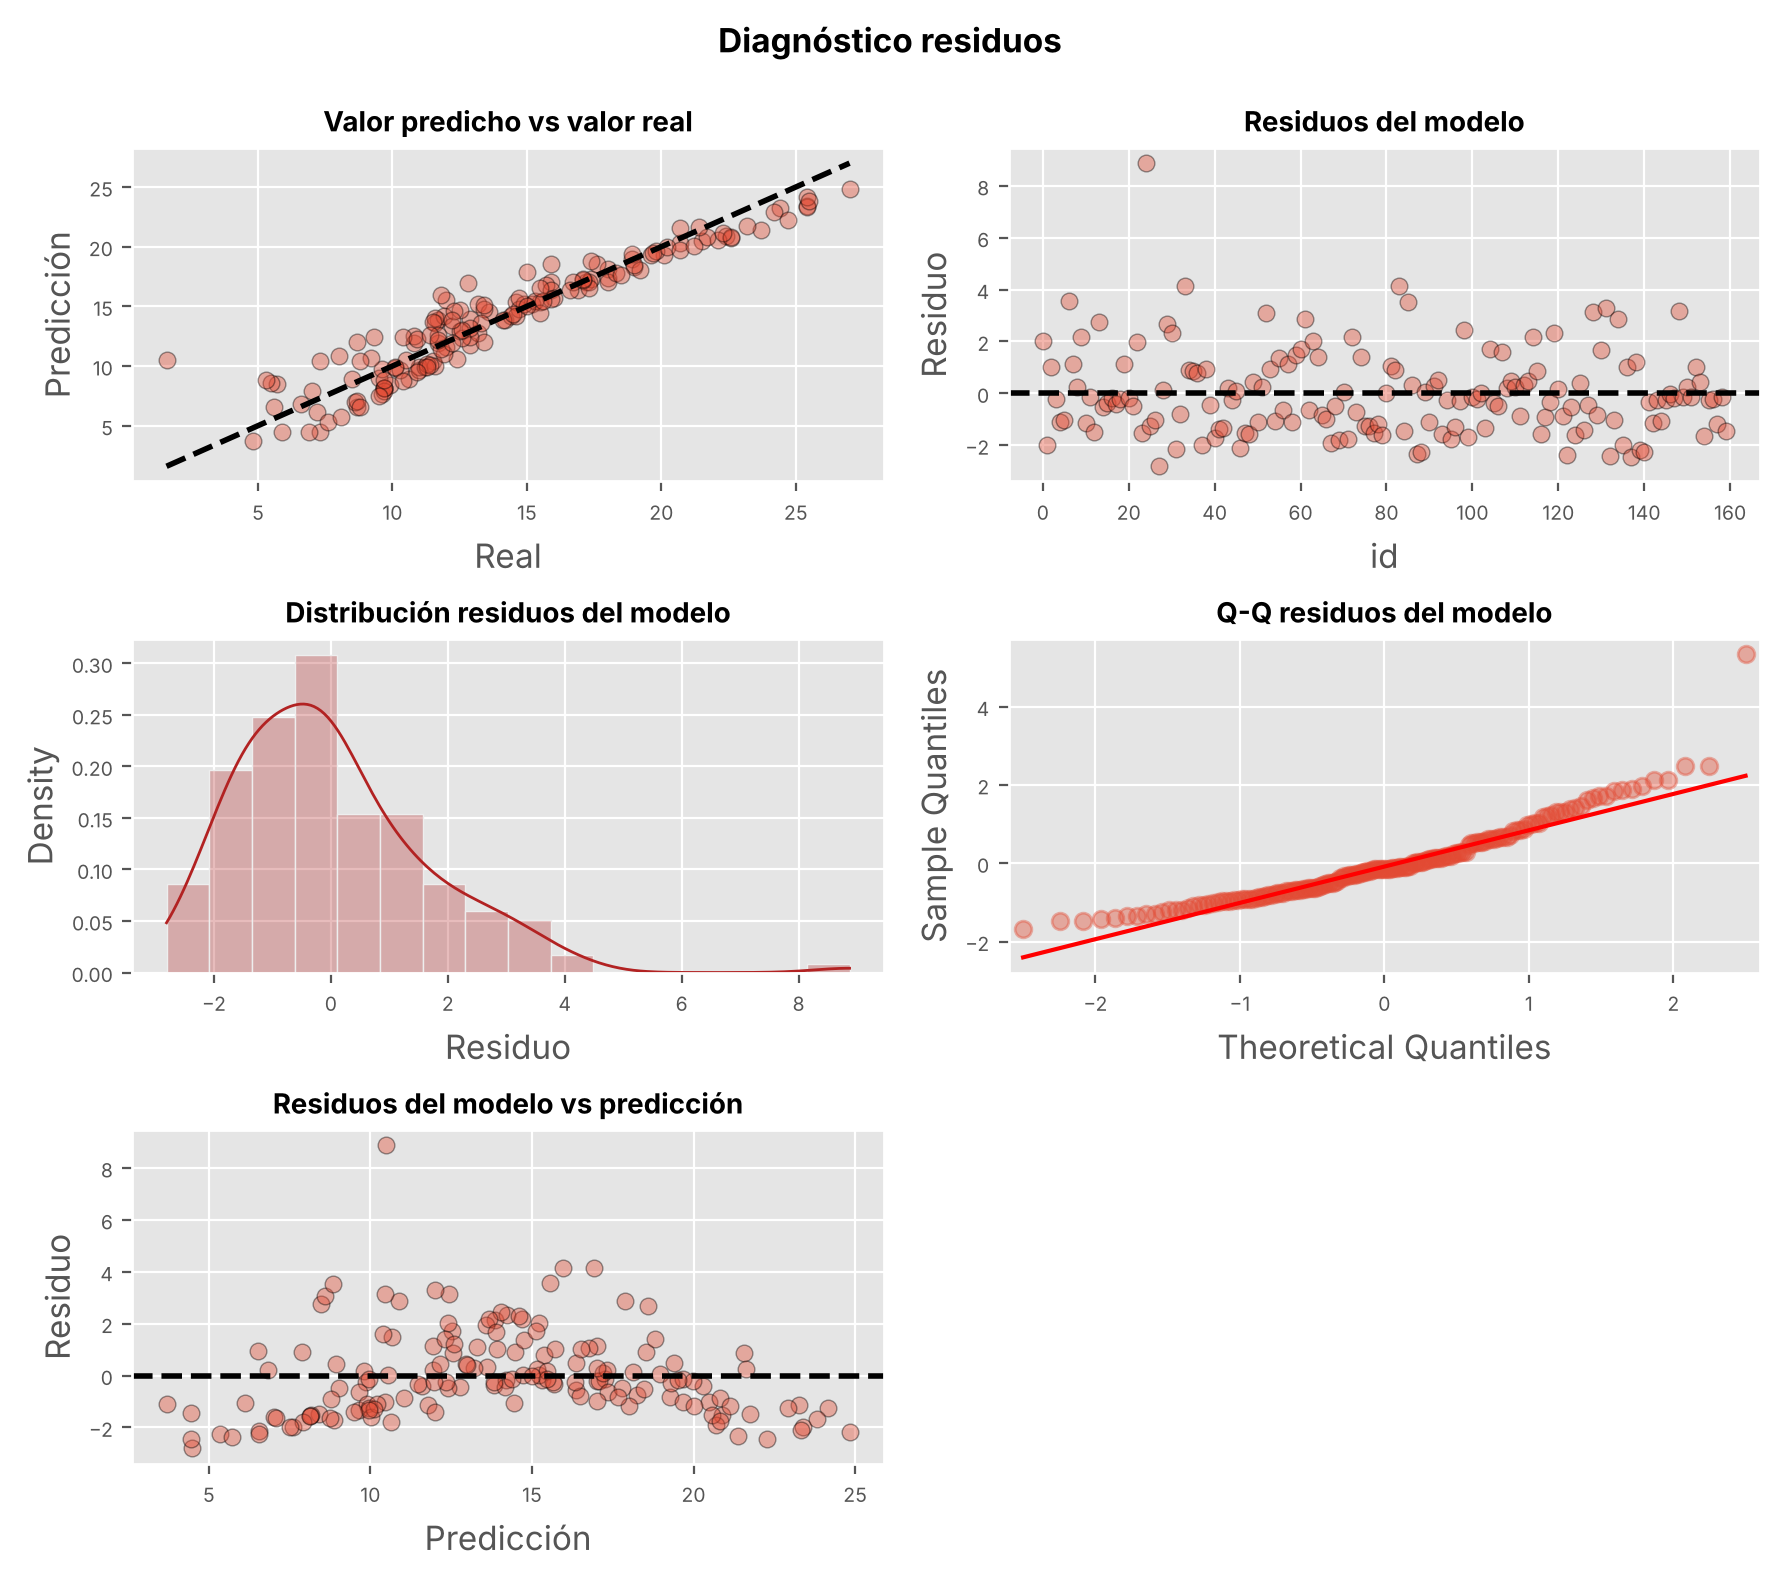

In [ ]:
# Gráficos
# ==============================================================================
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(9, 8))

axes[0, 0].scatter(y_train, prediccion_train, edgecolors=(0, 0, 0), alpha = 0.4)
axes[0, 0].plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()],
                linestyle='--', color = 'black', lw=2)
axes[0, 0].set_title('Valor predicho vs valor real', fontsize = 10, fontweight = "bold")
axes[0, 0].set_xlabel('Real')
axes[0, 0].set_ylabel('Predicción')
axes[0, 0].tick_params(labelsize = 7)

axes[0, 1].scatter(list(range(len(y_train))), residuos_train,
                   edgecolors=(0, 0, 0), alpha = 0.4)
axes[0, 1].axhline(y = 0, linestyle = '--', color = 'black', lw=2)
axes[0, 1].set_title('Residuos del modelo', fontsize = 10, fontweight = "bold")
axes[0, 1].set_xlabel('id')
axes[0, 1].set_ylabel('Residuo')
axes[0, 1].tick_params(labelsize = 7)

sns.histplot(
    data    = residuos_train,
    stat    = "density",
    kde     = True,
    line_kws= {'linewidth': 1},
    color   = "firebrick",
    alpha   = 0.3,
    ax      = axes[1, 0]
)

axes[1, 0].set_title('Distribución residuos del modelo', fontsize = 10,
                     fontweight = "bold")
axes[1, 0].set_xlabel("Residuo")
axes[1, 0].tick_params(labelsize = 7)


sm.qqplot(
    residuos_train,
    fit   = True,
    line  = 'q',
    ax    = axes[1, 1],
    color = 'firebrick',
    alpha = 0.4,
    lw    = 2
)
axes[1, 1].set_title('Q-Q residuos del modelo', fontsize = 10, fontweight = "bold")
axes[1, 1].tick_params(labelsize = 7)

axes[2, 0].scatter(prediccion_train, residuos_train,
                   edgecolors=(0, 0, 0), alpha = 0.4)
axes[2, 0].axhline(y = 0, linestyle = '--', color = 'black', lw=2)
axes[2, 0].set_title('Residuos del modelo vs predicción', fontsize = 10, fontweight = "bold")
axes[2, 0].set_xlabel('Predicción')
axes[2, 0].set_ylabel('Residuo')
axes[2, 0].tick_params(labelsize = 7)

# Se eliminan los axes vacíos
fig.delaxes(axes[2,1])

fig.tight_layout()
plt.subplots_adjust(top=0.9)
fig.suptitle('Diagnóstico residuos', fontsize = 12, fontweight = "bold");

Los residuos no parecen distribuirse de forma aleatoria en torno a cero, sin mantener aproximadamente la misma variabilidad a lo largo del eje X. Este patrón apunta a una falta de homocedasticidad y de distribución normal.

##Predicciones


Una vez entrenado el modelo, se pueden obtener predicciones para nuevos datos. Los modelos de statsmodels permiten calcular los intervalos de confianza asociados a cada predicción.

In [ ]:
# Predicciones con intervalo de confianza
# ==============================================================================
predicciones = modelo.get_prediction(exog = X_train).summary_frame(alpha=0.05)
predicciones.head(4)

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
146,15.231643,0.248325,14.741154,15.722132,11.880621,18.582665
32,7.615382,0.247198,7.127119,8.103645,4.264685,10.966079
43,13.928155,0.213535,13.506384,14.349927,10.586500,17.269810
99,17.001020,0.210052,16.586127,17.415913,13.660226,20.341814


##Error de test

In [ ]:
# Error de test del modelo
# ==============================================================================
X_test = sm.add_constant(X_test, prepend=True)
predicciones = modelo.predict(exog = X_test)
rmse = np.sqrt(mean_squared_error(
        y_true  = y_test,
        y_pred  = predicciones
       ))
print("")
print(f"El error (rmse) de test es: {rmse}")


El error (rmse) de test es: 1.6956207500101195
